In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
file = r"../Dataset/Cleaned_Academic_Probation_Project.xlsx"

df = pd.read_excel(
    file,
    sheet_name="Master_Education_Data (2)"
)

print("Dataset Loaded Successfully")
print(df.shape)

Dataset Loaded Successfully
(10000, 16)


In [4]:
print(df.head())

  Student_ID        Student_Name  Gender Department  Semester  \
0      S0001            Ajay Das    Male      AI&DS         8   
1      S0002     Pavithra Murthy  Female         IT         1   
2      S0003         Sandhya Das  Female        EEE         5   
3      S0004  Rekha Balakrishnan  Female      AI&DS         3   
4      S0005        Balaji Gupta    Male        EEE         5   

   Attendance_Percentage   GPA  Assignment_Score  Quiz_Score  Internal_Marks  \
0                   57.0  6.67                76          38              95   
1                   83.0  7.08                91          62              41   
2                   72.0  6.20                83          87              55   
3                   67.0  6.08                55          91              89   
4                   44.0  2.31                84          62              80   

   LMS_Login_Count  Study_Hours_Per_Week  Backlog_Count      Last_Login_Date  \
0               41                    35        

In [5]:
print("Average GPA:")
print(round(df['GPA'].mean(), 2))

print("\nAverage Attendance:")
print(round(df['Attendance_Percentage'].mean(), 2))

print("\nAverage Study Hours:")
print(round(df['Study_Hours_Per_Week'].mean(), 2))

print("\nAverage LMS Login Count:")
print(round(df['LMS_Login_Count'].mean(), 2))

Average GPA:
5.71

Average Attendance:
69.99

Average Study Hours:
20.17

Average LMS Login Count:
80.25


In [6]:
dept_gpa = (
    df.groupby('Department')['GPA']
    .mean()
    .sort_values(ascending=False)
)

print(dept_gpa)

Department
IT       5.764775
CIVIL    5.762739
CSE      5.748819
ECE      5.744151
MECH     5.684135
EEE      5.632419
AI&DS    5.613847
Name: GPA, dtype: float64


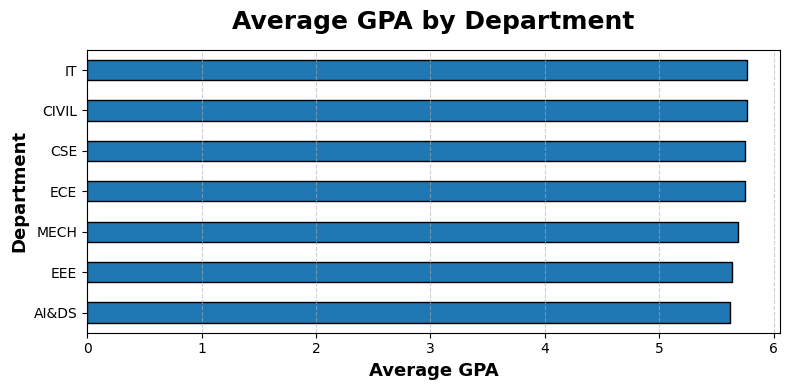

In [7]:
plt.figure(figsize=(8,4))

dept_gpa.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title(
    "Average GPA by Department",
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel(
    "Average GPA",
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    "Department",
    fontsize=13,
    fontweight='bold'
)

plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.6
)

plt.tight_layout()

plt.savefig(
    "Output_Charts/Department_GPA.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [8]:
dept_attendance = (
    df.groupby('Department')['Attendance_Percentage']
    .mean()
    .sort_values(ascending=False)
)

print(dept_attendance)

Department
AI&DS    71.094911
MECH     70.417363
IT       70.123953
ECE      69.837452
CSE      69.681258
EEE      69.564673
CIVIL    69.235969
Name: Attendance_Percentage, dtype: float64


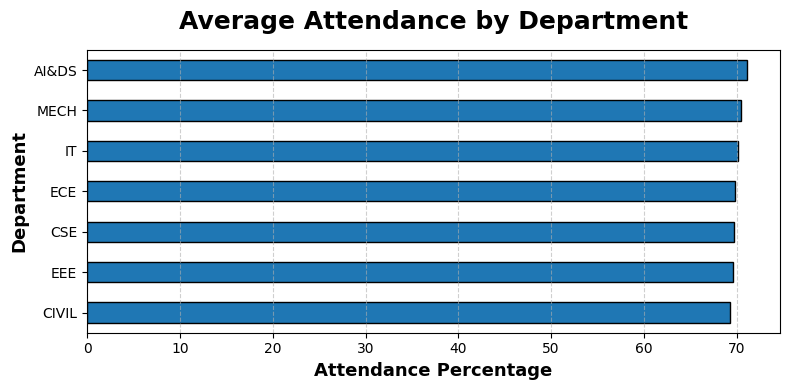

In [9]:
plt.figure(figsize=(8,4))

dept_attendance.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title(
    "Average Attendance by Department",
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel(
    "Attendance Percentage",
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    "Department",
    fontsize=13,
    fontweight='bold'
)

plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.6
)

plt.tight_layout()

plt.savefig(
    "Output_Charts/Department_Attendance.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [10]:
probation_count = (
    df[df['Probation_Status'] == 'Yes']
    .groupby('Department')
    .size()
    .sort_values(ascending=False)
)

print(probation_count)

Department
ECE      1164
EEE      1154
CIVIL    1134
CSE      1129
MECH     1116
IT       1094
AI&DS    1090
dtype: int64


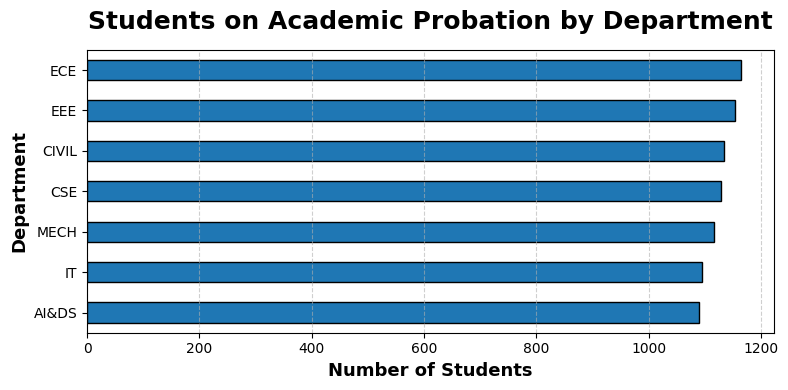

In [11]:
plt.figure(figsize=(8,4))

probation_count.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title(
    "Students on Academic Probation by Department",
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel(
    "Number of Students",
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    "Department",
    fontsize=13,
    fontweight='bold'
)

plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.6
)

plt.tight_layout()

plt.savefig(
    "Output_Charts/Probation_By_Department.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

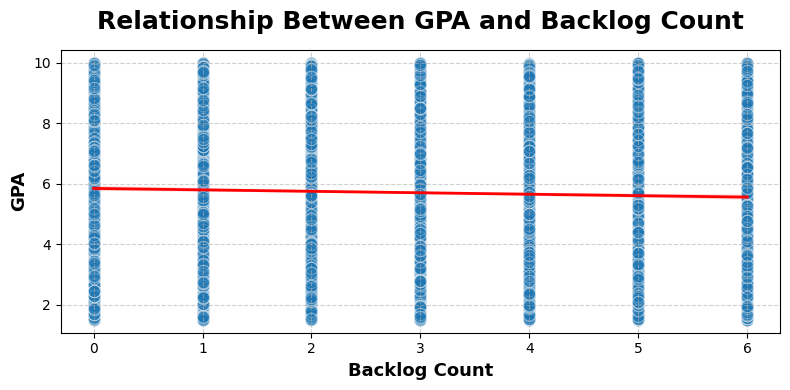

In [12]:
import seaborn as sns

plt.figure(figsize=(8,4))

sns.scatterplot(
    data=df,
    x='Backlog_Count',
    y='GPA',
    alpha=0.5,
    s=80
)

sns.regplot(
    data=df,
    x='Backlog_Count',
    y='GPA',
    scatter=False,
    color='red',
    line_kws={'linewidth':2}
)

plt.title(
    "Relationship Between GPA and Backlog Count",
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel(
    "Backlog Count",
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    "GPA",
    fontsize=13,
    fontweight='bold'
)

plt.grid(
    linestyle='--',
    alpha=0.6
)

plt.tight_layout()

plt.savefig(
    "Output_Charts/GPA_vs_Backlog.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [13]:
# ==========================================
# 1. Detailed Performance Metrics
# ==========================================

performance_metrics = pd.DataFrame({
    'Metric': [
        'GPA',
        'Attendance Percentage',
        'Study Hours Per Week',
        'LMS Login Count'
    ],
    'Minimum': [
        df['GPA'].min(),
        df['Attendance_Percentage'].min(),
        df['Study_Hours_Per_Week'].min(),
        df['LMS_Login_Count'].min()
    ],
    'Average': [
        df['GPA'].mean(),
        df['Attendance_Percentage'].mean(),
        df['Study_Hours_Per_Week'].mean(),
        df['LMS_Login_Count'].mean()
    ],
    'Maximum': [
        df['GPA'].max(),
        df['Attendance_Percentage'].max(),
        df['Study_Hours_Per_Week'].max(),
        df['LMS_Login_Count'].max()
    ]
})

print(performance_metrics.round(2))

                  Metric  Minimum  Average  Maximum
0                    GPA      1.5     5.71     10.0
1  Attendance Percentage     40.0    69.99    100.0
2   Study Hours Per Week      1.0    20.17     40.0
3        LMS Login Count      1.0    80.25    250.0


In [14]:
median_metrics = {
    'GPA': df['GPA'].median(),
    'Attendance': df['Attendance_Percentage'].median(),
    'Study Hours': df['Study_Hours_Per_Week'].median(),
    'LMS Login Count': df['LMS_Login_Count'].median()
}

print("\nMedian Performance Metrics:")
for metric, value in median_metrics.items():
    print(f"{metric}: {value:.2f}")


Median Performance Metrics:
GPA: 5.69
Attendance: 70.00
Study Hours: 20.00
LMS Login Count: 78.00


In [15]:
std_metrics = {
    'GPA': df['GPA'].std(),
    'Attendance': df['Attendance_Percentage'].std(),
    'Study Hours': df['Study_Hours_Per_Week'].std(),
    'LMS Login Count': df['LMS_Login_Count'].std()
}

print("\nStandard Deviation:")
for metric, value in std_metrics.items():
    print(f"{metric}: {value:.2f}")


Standard Deviation:
GPA: 2.40
Attendance: 17.35
Study Hours: 11.43
LMS Login Count: 49.43


In [16]:
dept_gpa_stats = df.groupby('Department')['GPA'].agg(
    ['min', 'mean', 'median', 'max', 'std']
).round(2)

print(dept_gpa_stats)

             min  mean  median    max   std
Department                                 
AI&DS       1.50  5.61    5.55  10.00  2.35
CIVIL       1.51  5.76    5.78  10.00  2.40
CSE         1.51  5.75    5.70   9.99  2.40
ECE         1.50  5.74    5.69  10.00  2.42
EEE         1.51  5.63    5.50   9.98  2.41
IT          1.50  5.76    5.86  10.00  2.42
MECH        1.50  5.68    5.76  10.00  2.40


In [17]:
dept_attendance_stats = df.groupby('Department')['Attendance_Percentage'].agg(
    ['min', 'mean', 'median', 'max', 'std']
).round(2)

print(dept_attendance_stats)

              min   mean  median     max    std
Department                                     
AI&DS       40.00  71.09   71.26  100.00  17.27
CIVIL       40.00  69.24   69.00  100.00  17.28
CSE         40.01  69.68   69.67  100.00  17.23
ECE         40.00  69.84   69.68  100.00  17.59
EEE         40.03  69.56   69.81  100.00  17.32
IT          40.00  70.12   70.15   99.98  17.33
MECH        40.00  70.42   71.04  100.00  17.37


Day 4 — Performance Analysis Insights

1. Overall Performance

   Calculated the average GPA to understand the overall academic performance of students.
  Calculated average attendance, study hours, and LMS login count to understand academic performance and student engagement.

2. Department-wise GPA Analysis

Used department-wise average GPA to compare academic performance between departments.
The department with a higher average GPA indicates relatively better overall academic performance, while a lower average indicates an area that may require attention.

3. Department-wise Attendance Analysis

Compared average attendance across departments.
This helps identify departments with relatively lower attendance that may need closer monitoring.

4. Academic Probation Analysis

Filtered students whose Probation_Status = "Yes".
Counted probation students department-wise.
This helps identify departments having a relatively higher number of students requiring academic intervention.

5. GPA vs Backlog Analysis

Used a scatter plot to study the relationship between Backlog_Count and GPA.
Added a regression line to identify the overall trend.
In your chart, the line is slightly downward, indicating a weak negative trend: as backlog count increases, GPA tends to decrease.